Исследование и анализ датасета с Kaggle (https://www.kaggle.com/datasets/harishyadav0506/impact-of-social-media-on-life/data) с использованием pandas и Seaborn.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
#импорт необходимых библиотек

In [2]:
data_path = "data/Social_media_impact_on_life.csv" # исп. относительного пути для импорта
df = pd.read_csv(data_path)

In [3]:
df.head() # можно использовать df.tail()

,Student_ID,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
0,STU_2024000,19,Female,Undergraduate,Snapchat,7.5,1.5,Smartphone,5.9,2,True,Always,20.0,73,2.73,Neutral
1,STU_2024001,19,Female,Undergraduate,Instagram,4.6,1.3,Smartphone,7.9,3,True,Sometimes,17.0,90,3.21,Beneficial
2,STU_2024002,17,Female,High School,TikTok,10.9,1.7,Smartphone,5.2,1,True,Frequently,18.0,70,3.00,Neutral
3,STU_2024003,16,Female,High School,YouTube,6.0,2.3,Tablet,7.6,4,True,Sometimes,15.0,82,3.42,Beneficial
4,STU_2024004,17,Male,High School,LinkedIn,3.3,2.6,Smartphone,7.6,4,True,Never,16.0,84,3.41,Beneficial


In [4]:
df.shape

(4500, 16)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4500 entries, 0 to 4499
Data columns (total 16 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Student_ID                   4500 non-null   str    
 1   Age                          4500 non-null   int64  
 2   Gender                       4500 non-null   str    
 3   Academic_Level               4500 non-null   str    
 4   Primary_Platform             4500 non-null   str    
 5   Daily_Usage_Hours            4500 non-null   float64
 6   Weekend_Extra_Hours          4500 non-null   float64
 7   Device_Type                  4500 non-null   str    
 8   Sleep_Duration_Hours         4500 non-null   float64
 9   Sleep_Quality_Score          4500 non-null   int64  
 10  Late_Night_Usage             4500 non-null   bool   
 11  Social_Comparison_Frequency  4500 non-null   str    
 12  Perceived_Stress_Score       4454 non-null   float64
 13  Mental_Health_Index          

In [6]:
df['Gender'].value_counts()

Gender
Female               2234
Male                 2051
Non-Binary            122
Prefer not to say      93
Name: count, dtype: int64

In [7]:
df[df['Academic_Performance_GPA'].isna()]['Academic_Level'].value_counts() 

Academic_Level
Undergraduate    56
High School      27
Postgraduate      2
Name: count, dtype: int64

In [8]:
df['Academic_Performance_GPA'].isna().groupby(df['Academic_Level']).mean() * 100 

Academic_Level
High School      1.828030
Postgraduate     0.813008
Undergraduate    2.016565
Name: Academic_Performance_GPA, dtype: float64

In [9]:
df.isna().sum()

Student_ID                      0
Age                             0
Gender                          0
Academic_Level                  0
Primary_Platform                0
Daily_Usage_Hours               0
Weekend_Extra_Hours             0
Device_Type                     0
Sleep_Duration_Hours            0
Sleep_Quality_Score             0
Late_Night_Usage                0
Social_Comparison_Frequency     0
Perceived_Stress_Score         46
Mental_Health_Index             0
Academic_Performance_GPA       85
Overall_Impact                  0
dtype: int64

Посмотрели, в каких группах и в каком процентном соотношении есть пропуски. Проценты пропусков в каждой группе незначительные, скорее всего, пропуски случайные. На странице датасета не описано, как проводился опрос.Пропуски есть только в двух колонках: Perceived_Stress_Score (46, ~1%) и Academic_Performance_GPA (85, ~1,9%). Доля пропусков GPA почти одинакова во всех группах по уровню обучения (0,8–2%), поэтому пропуски, скорее всего, случайные, и строки с ними исключаются только там, где используется эта колонка. Есть основания предполагать, что данные синтетические.

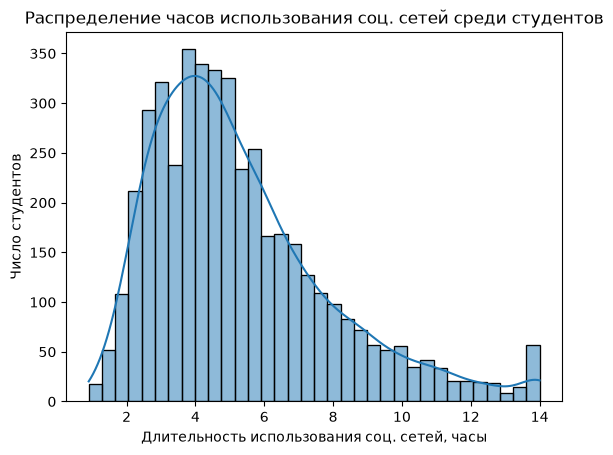

In [10]:
sns.histplot(df['Daily_Usage_Hours'], kde = True)
plt.title('Распределение часов использования соц. сетей среди студентов')
plt.ylabel('Число студентов')
plt.xlabel('Длительность использования соц. сетей, часы')
plt.show()

In [11]:
df['Daily_Usage_Hours'].agg(['mean', 'median'])

mean      5.295933
median    4.700000
Name: Daily_Usage_Hours, dtype: float64

In [12]:
df['Daily_Usage_Hours'].value_counts().sort_index().tail()

Daily_Usage_Hours
13.4     6
13.5     4
13.6     2
13.9     2
14.0    55
Name: count, dtype: int64

Среднее немного больше медианы, т.к справа есть 'Хвост'. На значении 14 (максимум шкалы) скопилось 55 студентов. Это характерно для синтетических данных.

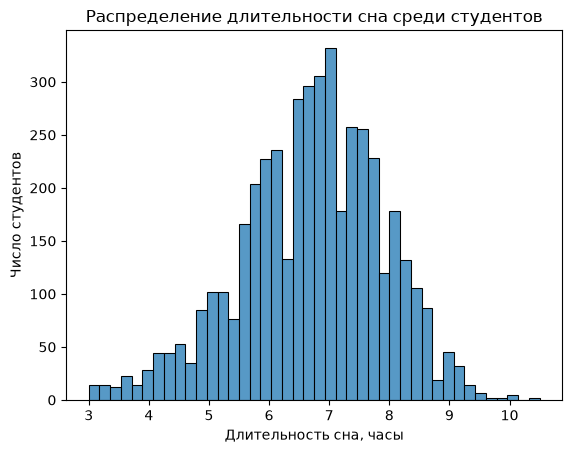

In [13]:
sns.histplot(df['Sleep_Duration_Hours'])
plt.title('Распределение длительности сна среди студентов')
plt.ylabel('Число студентов')
plt.xlabel('Длительность сна, часы')
plt.show()

In [14]:
df['Sleep_Duration_Hours'].agg(['mean','median']) 

mean      6.701333
median    6.800000
Name: Sleep_Duration_Hours, dtype: float64

Распределение симметричное, т.к нет "Хвостов".

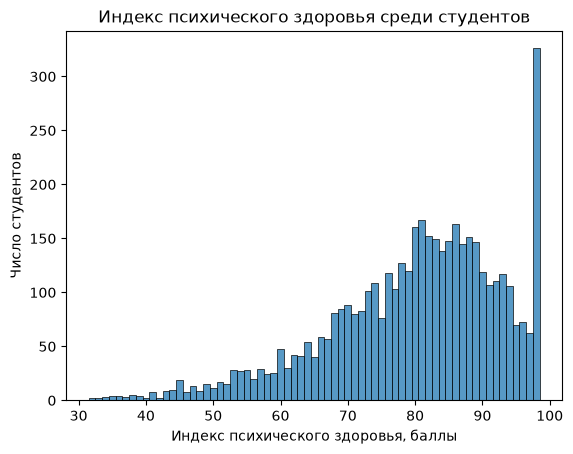

In [15]:
sns.histplot(df['Mental_Health_Index'], discrete = True)
plt.title('Индекс психического здоровья среди студентов')
plt.ylabel('Число студентов')
plt.xlabel('Индекс психического здоровья, баллы')
plt.show()

In [16]:
df['Mental_Health_Index'].agg(['mean','median'])

mean      79.873111
median    82.000000
Name: Mental_Health_Index, dtype: float64

In [17]:
df['Mental_Health_Index'].value_counts().sort_index().tail()

Mental_Health_Index
94    106
95     70
96     73
97     62
98    326
Name: count, dtype: int64

**Вывод**

Видим, что среднее (~79.9) немного ниже медианы (~82). У небольшой группы студентов индекс психического здоровья заметно ниже, чем у большинства и они тянут среднее вниз. На значении 98 (максимум шкалы) скопилось 326 студентов против 62 на 97. Такой пик характерен для обрезки значений при генерации данных.

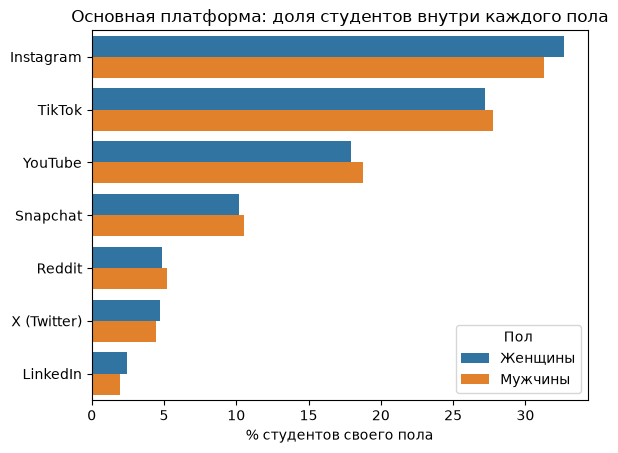

In [18]:
two_genders = df[df['Gender'].isin(['Female', 'Male'])]

pct = (two_genders.groupby('Gender')['Primary_Platform']
       .value_counts(normalize=True)
       .mul(100)
       .reset_index(name='percent'))

pct['Gender'] = pct['Gender'].map({'Female': 'Женщины', 'Male': 'Мужчины'})

order = df['Primary_Platform'].value_counts().index

sns.barplot(data=pct, y='Primary_Platform', x='percent', hue='Gender', order=order)
plt.title('Основная платформа: доля студентов внутри каждого пола')
plt.xlabel('% студентов своего пола')
plt.ylabel('')
plt.legend(title='Пол')
plt.show()

Instagram, TikTok, Youtube и Snapchat - самые популярные платформы среди студентов, далее идут Reddit и X (Twitter). Доли платформ внутри каждого пола почти одинаковы, то есть предпочтения от пола практически не зависят. Группы Non-Binary и Prefer not to say исключены из-за малого размера.

In [19]:
tenths = (df['Sleep_Duration_Hours'] * 10).round().astype(int) % 10
tenths.value_counts().sort_index()

Sleep_Duration_Hours
0    472
1    474
2    457
3    407
4    460
5    437
6    436
7    455
8    473
9    429
Name: count, dtype: int64

В реальных опросах люди называют круглые значения, поэтому среди ответов о сне преобладали бы десятые .0 и .5. Здесь все десятые доли от .0 до .9 встречаются примерно одинаково (по ~450 раз). Это ещё один признак того, что значения сгенерированы, а не получены от респондентов.